# Ruta para mejorar el AUROC

BolsaLAB · Grupo 10

In [1]:
import sys
from pathlib import Path

# Raíz del proyecto: la primera carpeta hacia arriba que tenga pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

from bolsalab.config import AUROC_NOISE, MAX_OVERFIT_GAP
from bolsalab.modeling.train import BENCHMARK_FILE, TRAINING_FILE, split_data
from bolsalab.modeling.transformers import FeatureEngineer
from bolsalab.modeling.tuning import TUNING_FILE

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#555555"
STAGE_COLORS = {"Parada temprana": "#2a78d6", "Poda": "#1b9e77",
                "Optuna": "#7b5ea7", "Variables": "#8a8a85", "Literatura": "#c2185b",
                "Etiqueta": "#8d6e63"}
STAGES = {1: "Parada temprana", 2: "Poda", 8: "Optuna", 5: "Variables", 9: "Literatura", 10: "Etiqueta"}
MODEL_NAMES = {"xgboost": "XGBoost", "lightgbm": "LightGBM", "catboost": "CatBoost",
               "logistic": "Regresión logística", "random_forest": "Random Forest",
               "neural_net": "Red neuronal", "trivial": "Naive (ingenuo)"}
TEST_NAMES = {"total_aciertos": "Total de aciertos",
              "confianza_sin_sustento": "Confianza sin sustento",
              "hombre_pocos_aciertos": "Hombre con pocos aciertos",
              "poco_colchon": "Poco colchón financiero",
              "tramos_como_grupos": "Tramos como grupos",
              "solo_app": "Solo lo que pregunta la app",
              "aleatoriedad": "XGBoost con aleatoriedad",
              "xgboost_catboost_logistica": "Promedio de 3 modelos",
              "tres_clases": "Tres clases"}


def fmt(value, digits=4):
    """Número con coma decimal."""
    return f"{value:.{digits}f}".replace(".", ",")


def thousands(value):
    """Entero con punto de miles."""
    return f"{value:,}".replace(",", ".")


def comma_axis(axis, digits):
    """Eje con coma decimal."""
    axis.set_major_formatter(FuncFormatter(lambda value, _: fmt(value, digits)))


# Fondo blanco para que los textos no queden tapados por las líneas de referencia
WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 1.5}


def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)


def dot_plot(ax, data, lines, label_column="label"):
    """AUROC ± 1 desviación de cada prueba, de arriba abajo, con líneas de referencia."""
    for i, row in enumerate(data.itertuples()):
        ax.errorbar(row.auroc, i, xerr=row.auroc_sd, fmt="o", color=STAGE_COLORS[row.stage],
                    markersize=8, capsize=4, linewidth=2)
        ax.text(row.auroc + row.auroc_sd + 0.0007, i, fmt(row.auroc),
                va="center", fontsize=9, color=GRAY, bbox=WHITE_BOX, zorder=5)
    for value, color, line_style, text in lines:
        ax.axvline(value, color=color, linestyle=line_style, linewidth=1.5, label=text)
    ax.set_yticks(range(len(data)), data[label_column])
    ax.invert_yaxis()
    ax.set_xlim(0.645, 0.670)
    comma_axis(ax.xaxis, 3)
    ax.set_xlabel("AUROC (validación anidada, media ± 1 desviación)")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
    style(ax)


# Lee los resultados ya guardados; este notebook no entrena nada.
# Si una prueba se repitió con --rerun, vale su última corrida.
results = pd.read_csv(TUNING_FILE).drop_duplicates("experiment", keep="last")
benchmark = pd.read_csv(BENCHMARK_FILE).set_index("model")

results["stage"] = results["step"].map(STAGES)
results["name"] = [TEST_NAMES.get(e.split("|")[1], MODEL_NAMES.get(e.split("|")[0]))
                   for e in results["experiment"]]
results["label"] = results["stage"] + " · " + results["name"]

official = benchmark.loc["xgboost"]
replace_at = official["auroc"] + official["auroc_sd"]
pruned = results.set_index("experiment").loc["xgboost|poda"]
adopt_at = pruned["auroc"] + AUROC_NOISE

official_line = (official["auroc"], ORANGE, "--", f"XGBoost oficial ({fmt(official['auroc'])})")
replace_line = (replace_at, GRAY, "-", f"Umbral de reemplazo ({fmt(replace_at)})")

# Orden de la ruta: parada temprana, poda, Optuna, variables, literatura y etiqueta
route = results.set_index("step").loc[[1, 2, 8, 5, 9, 10]].reset_index()
tuning_rows = route[route["step"].isin([1, 2, 8])]
variable_rows = route[route["step"] == 5]
literature_rows = route[route["step"].isin([9, 10])]

C:\Repos\bolsalab\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Punto de partida

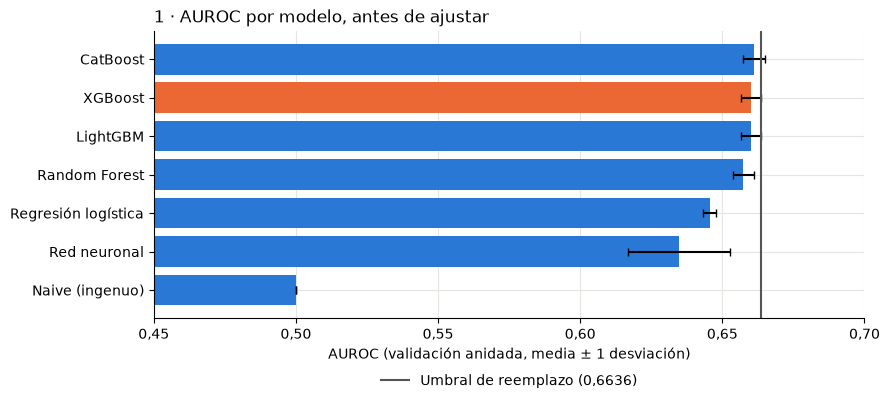

In [2]:
models = benchmark.sort_values("auroc")
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [ORANGE if m == "xgboost" else BLUE for m in models.index]
ax.barh([MODEL_NAMES[m] for m in models.index], models["auroc"], xerr=models["auroc_sd"],
        color=colors, capsize=3)
ax.axvline(replace_at, color=GRAY, linewidth=1.5, label=f"Umbral de reemplazo ({fmt(replace_at)})")
ax.set_xlim(0.45, 0.70)
comma_axis(ax.xaxis, 2)
ax.set_xlabel("AUROC (validación anidada, media ± 1 desviación)")
ax.set_title("1 · AUROC por modelo, antes de ajustar", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
style(ax)
plt.tight_layout()
plt.show()

## 2 · Ajustar el modelo

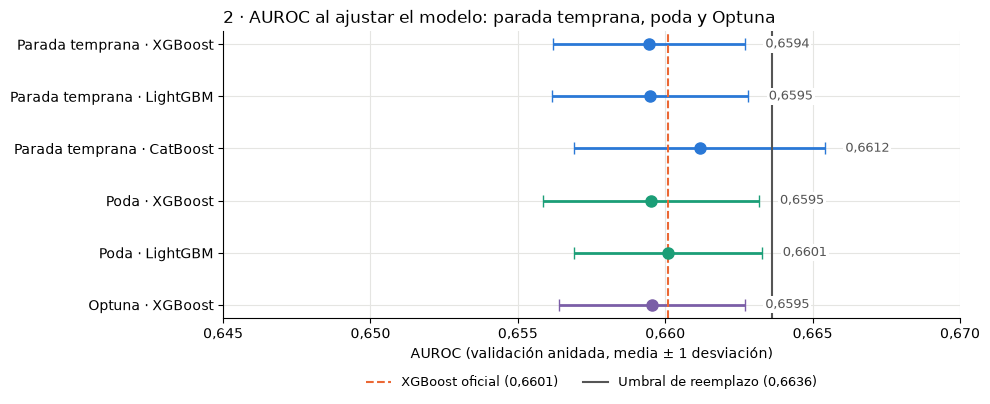

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
dot_plot(ax, tuning_rows, [official_line, replace_line])
ax.set_title("2 · AUROC al ajustar el modelo: parada temprana, poda y Optuna", loc="left")
plt.tight_layout()
plt.show()

## 3 · Lo que sí se movió al ajustar

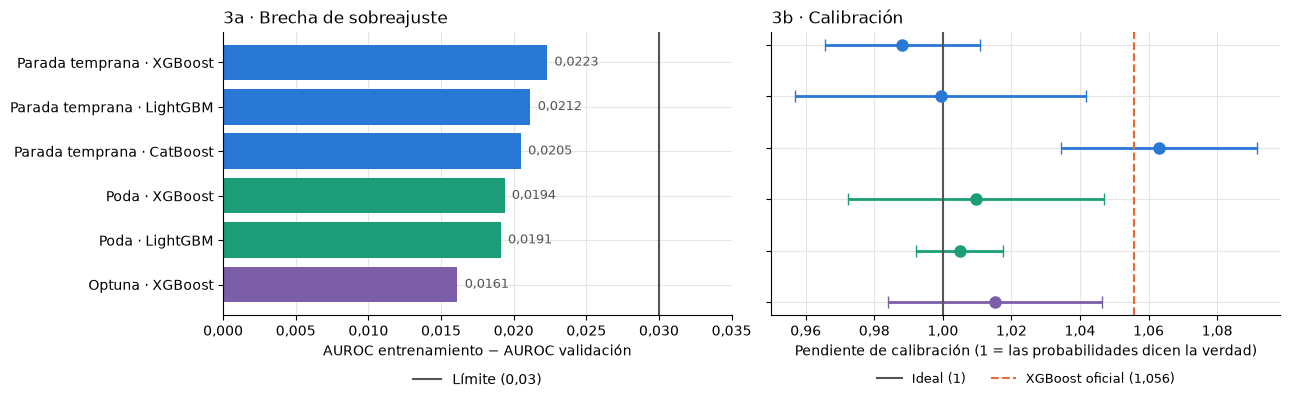

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2))
y = range(len(tuning_rows))
bar_colors = [STAGE_COLORS[s] for s in tuning_rows["stage"]]

left.barh(y, tuning_rows["overfit_gap"], color=bar_colors)
for i, value in enumerate(tuning_rows["overfit_gap"]):
    left.text(value + 0.0005, i, fmt(value), va="center", fontsize=9, color=GRAY)
left.axvline(MAX_OVERFIT_GAP, color=GRAY, linewidth=1.5, label=f"Límite ({fmt(MAX_OVERFIT_GAP, 2)})")
left.set_yticks(y, tuning_rows["label"])
left.invert_yaxis()
left.set_xlim(0, 0.035)
comma_axis(left.xaxis, 3)
left.set_xlabel("AUROC entrenamiento − AUROC validación")
left.set_title("3a · Brecha de sobreajuste", loc="left")
left.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
style(left)

for i, row in enumerate(tuning_rows.itertuples()):
    right.errorbar(row.calibration_slope, i, xerr=row.calibration_slope_sd, fmt="o",
                   color=STAGE_COLORS[row.stage], markersize=8, capsize=4, linewidth=2)
right.axvline(1, color=GRAY, linewidth=1.5, label="Ideal (1)")
right.axvline(official["calibration_slope"], color=ORANGE, linestyle="--", linewidth=1.5,
              label=f"XGBoost oficial ({fmt(official['calibration_slope'], 3)})")
right.set_yticks(range(len(tuning_rows)), [])
right.invert_yaxis()
comma_axis(right.xaxis, 2)
right.set_xlabel("Pendiente de calibración (1 = las probabilidades dicen la verdad)")
right.set_title("3b · Calibración", loc="left")
right.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
style(right)

plt.tight_layout()
plt.show()

## 4 · Variables nuevas: qué marcan

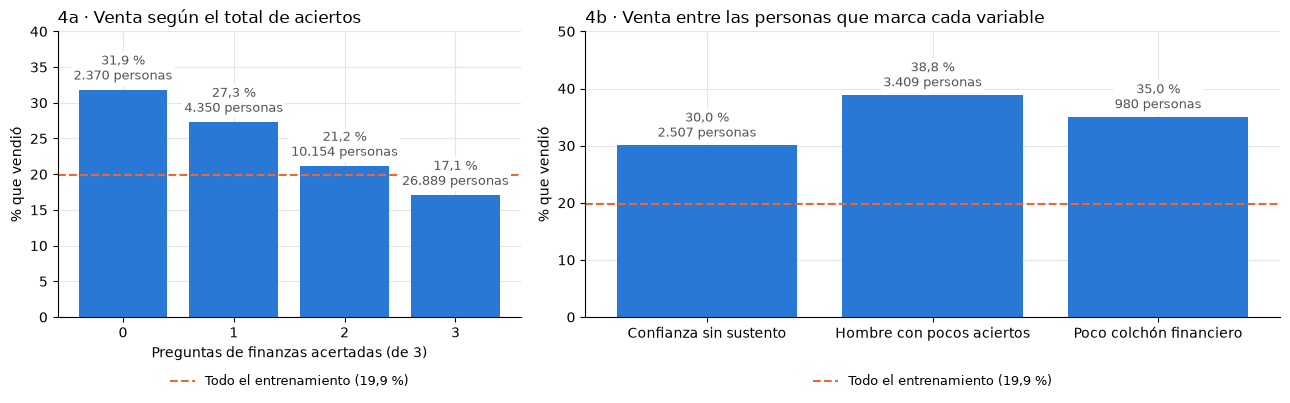

In [5]:
# Las variables nuevas se calculan solo con las personas de entrenamiento
table = pd.read_parquet(TRAINING_FILE)
X_train, X_test, y_train, y_test = split_data(table)
engineer = FeatureEngineer(add_correct_answers=True, unjustified_confidence=True,
                           man_with_few_correct=True, low_financial_cushion=True).fit(X_train)
X_new = engineer.transform(X_train)
base_rate = y_train.mean() * 100

by_correct = y_train.groupby(X_new["correct_answers"]).agg(["mean", "size"])
flags = {"Confianza sin sustento": "unjustified_confidence",
         "Hombre con pocos aciertos": "man_with_few_correct",
         "Poco colchón financiero": "low_financial_cushion"}
marked = {name: (y_train[X_new[column] == 1].mean() * 100, int((X_new[column] == 1).sum()))
          for name, column in flags.items()}

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 3]})

left.bar([str(n) for n in by_correct.index], by_correct["mean"] * 100, color=BLUE)
for i, (rate, n) in enumerate(zip(by_correct["mean"] * 100, by_correct["size"])):
    left.text(i, rate + 0.8, f"{fmt(rate, 1)} %\n{thousands(n)} personas",
              ha="center", va="bottom", fontsize=9, color=GRAY, bbox=WHITE_BOX, zorder=5)
left.axhline(base_rate, color=ORANGE, linestyle="--", linewidth=1.5,
             label=f"Todo el entrenamiento ({fmt(base_rate, 1)} %)")
left.set_ylim(0, 40)
left.set_xlabel("Preguntas de finanzas acertadas (de 3)")
left.set_ylabel("% que vendió")
left.set_title("4a · Venta según el total de aciertos", loc="left")
left.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9)
style(left)

names = list(marked)
rates = [marked[n][0] for n in names]
right.bar(names, rates, color=BLUE)
for i, n in enumerate(names):
    right.text(i, rates[i] + 0.8, f"{fmt(rates[i], 1)} %\n{thousands(marked[n][1])} personas",
               ha="center", va="bottom", fontsize=9, color=GRAY, bbox=WHITE_BOX, zorder=5)
right.axhline(base_rate, color=ORANGE, linestyle="--", linewidth=1.5,
              label=f"Todo el entrenamiento ({fmt(base_rate, 1)} %)")
right.set_ylim(0, 50)
right.set_ylabel("% que vendió")
right.set_title("4b · Venta entre las personas que marca cada variable", loc="left")
right.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9)
style(right)

plt.tight_layout()
plt.show()

## 5 · Variables nuevas: qué hicieron con el AUROC

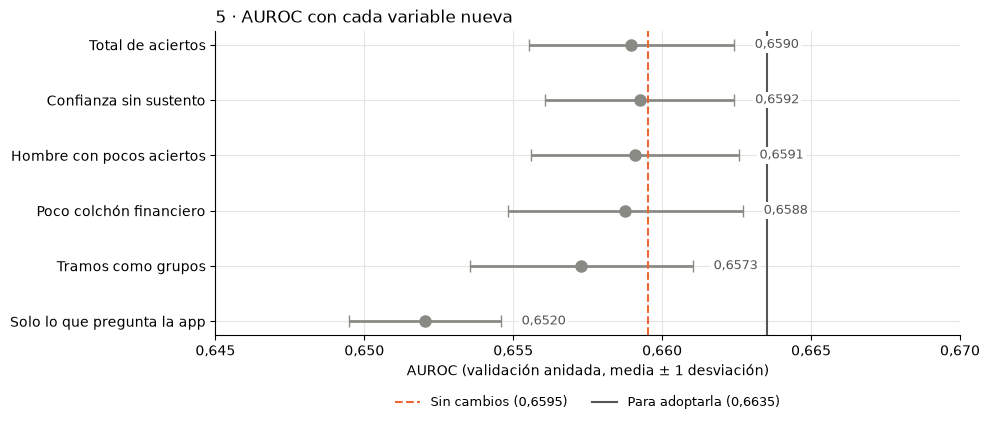

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
dot_plot(ax, variable_rows,
         [(pruned["auroc"], ORANGE, "--", f"Sin cambios ({fmt(pruned['auroc'])})"),
          (adopt_at, GRAY, "-", f"Para adoptarla ({fmt(adopt_at)})")],
         label_column="name")
ax.set_title("5 · AUROC con cada variable nueva", loc="left")
plt.tight_layout()
plt.show()

## 6 · Ideas de la literatura

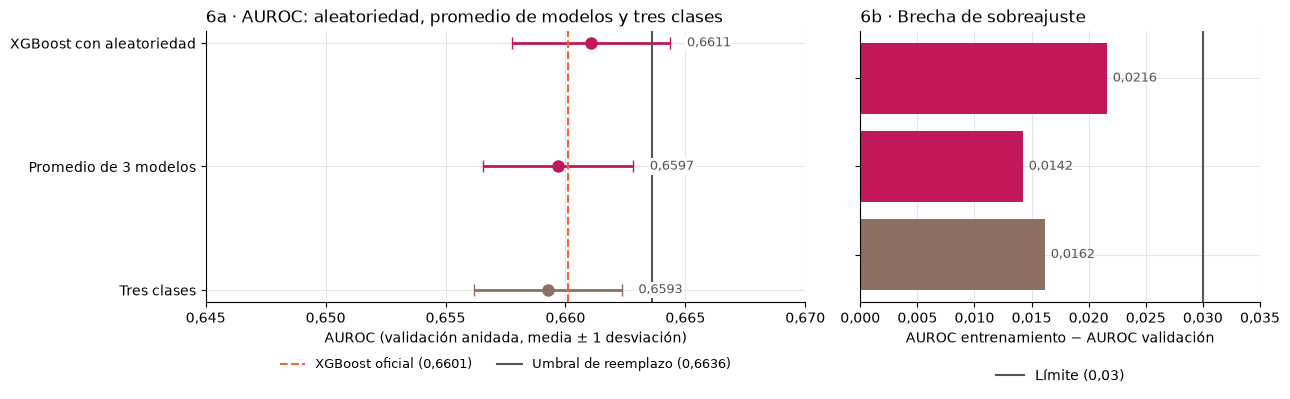

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 2]})
dot_plot(left, literature_rows, [official_line, replace_line], label_column="name")
left.set_title("6a · AUROC: aleatoriedad, promedio de modelos y tres clases", loc="left")

y = range(len(literature_rows))
right.barh(y, literature_rows["overfit_gap"], color=[STAGE_COLORS[s] for s in literature_rows["stage"]])
for i, value in enumerate(literature_rows["overfit_gap"]):
    right.text(value + 0.0005, i, fmt(value), va="center", fontsize=9, color=GRAY)
right.axvline(MAX_OVERFIT_GAP, color=GRAY, linewidth=1.5, label=f"Límite ({fmt(MAX_OVERFIT_GAP, 2)})")
right.set_yticks(y, [])
right.invert_yaxis()
right.set_xlim(0, 0.035)
comma_axis(right.xaxis, 3)
right.set_xlabel("AUROC entrenamiento − AUROC validación")
right.set_title("6b · Brecha de sobreajuste", loc="left")
right.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
style(right)

plt.tight_layout()
plt.show()

## 7 · Todo junto

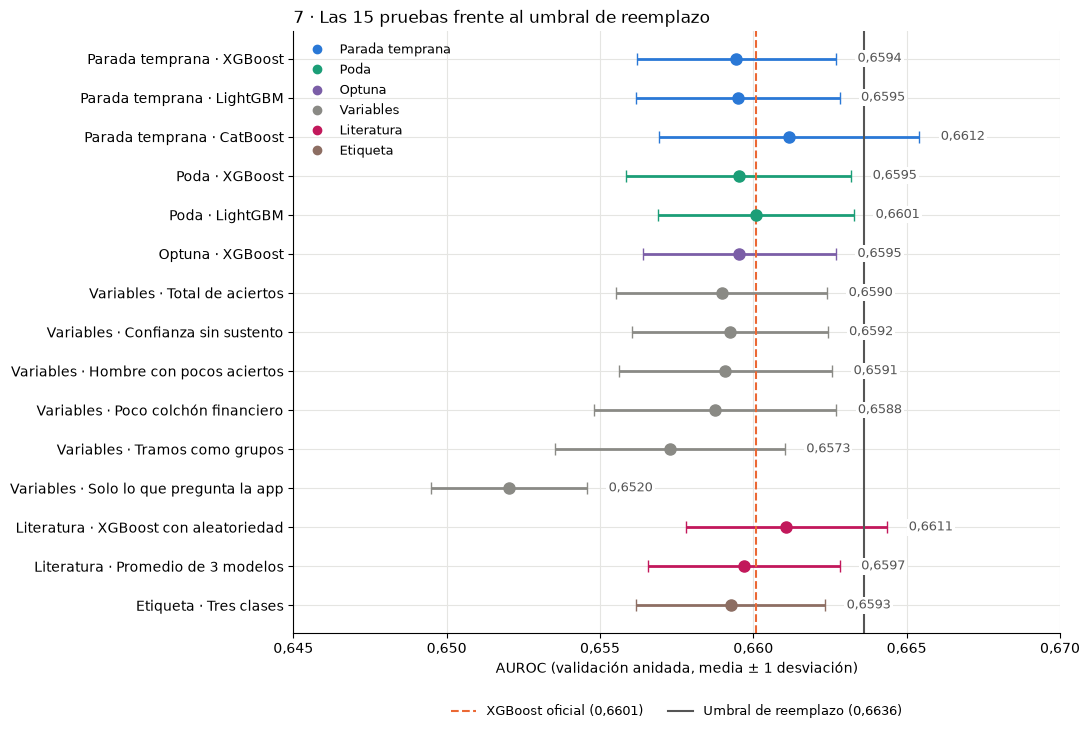

In [8]:
fig, ax = plt.subplots(figsize=(11, 7.4))
dot_plot(ax, route, [official_line, replace_line])
handles = [Line2D([], [], marker="o", linestyle="", color=c, label=s) for s, c in STAGE_COLORS.items()]
first = ax.legend(handles=handles, frameon=False, loc="upper left", fontsize=9)
ax.add_artist(first)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
ax.set_title(f"7 · Las {len(route)} pruebas frente al umbral de reemplazo", loc="left")
plt.tight_layout()
plt.show()